# Red neuronal (Keras) — predicción de `opinion`

Obligatorio MLSI 2026 S2. Esta notebook contiene:

1. Carga de datos
2. Preprocesamiento (código común en `obl_utils.py`)
3. Validación y métricas
4. Red neuronal: arquitectura, entrenamiento, baseline y búsqueda de hiperparámetros
5. Análisis del modelo elegido
6. Submission y resultado en Kaggle

La red se arma con Keras siguiendo el práctico de redes neuronales del curso (red secuencial *feedforward* con capas `Dense`, `Dropout` y `EarlyStopping`), adaptada a clasificación binaria y evaluada con la misma validación que el resto de los modelos.

## 1. Carga de datos

In [1]:
import os
import urllib.request

# El código común (preprocesamiento y evaluación) está en obl_utils.py.
# En Colab no está el archivo, así que se descarga del repo.
if not os.path.exists('obl_utils.py'):
    urllib.request.urlretrieve(
        'https://raw.githubusercontent.com/juanmareolon/OBL_ML/main/obl_utils.py', 'obl_utils.py')

import numpy as np
import pandas as pd
from obl_utils import *

# Carpetas de salida de esta notebook
CARPETA_RESULTADOS = 'resultados/Red_Neuronal'
CARPETA_KAGGLE = 'kaggle'
os.makedirs(CARPETA_RESULTADOS, exist_ok=True)
os.makedirs(CARPETA_KAGGLE, exist_ok=True)

train, test = cargar_datos()
X, y, X_test, ids_test = preparar_datos(train, test)

print('train:', train.shape, '| test:', test.shape)
print('X:', X.shape, '| X_test:', X_test.shape)
print('Balance de clases:', y.value_counts(normalize=True).round(3).to_dict())
X.head()

train: (3602, 14) | test: (1201, 14)
X: (3602, 15) | X_test: (1201, 15)
Balance de clases: {0: 0.506, 1: 0.494}


,budget_desconocido,log_budget,revenue_desconocido,log_revenue,log_roi,runtime,log_vote_count,log_popularity,anio,mes,sin_keywords,cant_keywords,main_genre_top10,original_language,director
0,0,18.064006,0,17.328879,0.391667,97.0,5.598422,2.657993,2002.0,10.0,0,8,Action,en,Betty Thomas
1,1,NaN,1,NaN,NaN,90.0,4.158883,1.767642,1992.0,5.0,0,4,Thriller,en,Tony Maylam
2,0,16.454568,0,15.446479,0.311093,90.0,4.234107,1.921864,2000.0,4.0,0,6,Drama,en,Davis Guggenheim
3,0,16.523561,0,18.384107,2.005155,96.0,6.928538,3.519225,2008.0,8.0,0,6,Drama,en,Woody Allen
4,0,19.336971,0,20.654943,1.555158,153.0,8.574329,4.604026,2009.0,7.0,0,7,Adventure,en,David Yates


## 2. Preprocesamiento

El código está en `obl_utils.py` y es el mismo para todas las notebooks de modelos, así la comparación entre modelos es justa. El motivo de cada decisión está detallado en `Arbol_Clasificacion.ipynb` (sección 2); acá va el resumen.

**Capa 1: limpieza fija (`limpiar`).** Transformaciones que no aprenden nada de los datos:

- `budget` y `revenue`: los 0 y los valores < 1000 pasan a NaN, y se agrega un indicador `*_desconocido`.
- `runtime`: los 0 pasan a NaN.
- `budget`, `revenue`, `vote_count` y `popularity`: `log1p`.
- Variables nuevas: `anio` y `mes` (de `release_date`), `log_roi`, `sin_keywords` y `cant_keywords`.
- Se descartan `status`, `original_title` y `overview`.

**Capa 2: pipeline de sklearn (`crear_preprocesador`).** Lo que *aprende* de los datos se ajusta solo con el train de cada fold:

- Numéricas: imputación por mediana + `StandardScaler`.
- `main_genre_top10` y `original_language`: one-hot (los idiomas con menos de 20 películas se agrupan).
- `director` no se usa (no mejoró el AUC del árbol).

**Qué cambia respecto de los otros modelos.** Nada, pero acá el preprocesamiento importa más que en los modelos de árboles. Una red neuronal, igual que la regresión logística, combina las variables con sumas ponderadas y se entrena con descenso por gradiente, así que es sensible a la escala: si una variable tomara valores mucho más grandes que otras, dominaría las sumas y el entrenamiento sería más lento e inestable. Por eso son necesarias la estandarización de las numéricas (media 0 y desvío 1) y el `log1p` de los montos. Además, la red no acepta valores faltantes ni categorías en texto, que se resuelven con la imputación y el one-hot. Las 27 columnas que salen del preprocesador son la entrada de la red.

## 3. Validación y métricas

**Validación: k-fold cross-validation estratificado** (`crear_cv()`), con 5 folds y `SEED = 42`. Todos los modelos usan exactamente los mismos folds.

- Cada película se usa para validar exactamente una vez, a diferencia del holdout (depende de una sola división al azar) y del repeated holdout (algunas películas se validan varias veces y otras ninguna).
- *Estratificado*: cada fold mantiene la proporción de clases (51/49).
- El preprocesador va dentro de un `Pipeline` junto al modelo (`crear_pipeline()`), así medianas, escalas y encodings se ajustan solo con el train de cada fold (sin *data leakage*).

**Métricas** (`evaluar()`): accuracy, precision, recall, F1 y AUC-ROC, con promedio y desvío entre folds. También se registra el AUC en train: si es mucho mayor que el de validación, el modelo está sobreajustando. La matriz de confusión se obtiene con `matriz_confusion()`, usando las predicciones de validación de cada fold.

La métrica principal para elegir es el **AUC**, porque es la que usa la competencia de Kaggle.

**Particularidad de la red: early stopping sin tocar el fold de validación.** Para decidir cuándo dejar de entrenar (sección 4.3), la red necesita un conjunto de validación propio. En cada fold se separa al azar el 15% del train del fold (estratificado) y se usa solo para el *early stopping*. El fold de validación de la CV queda sin usar hasta el final, igual que con los otros modelos, así que el AUC de validación sigue siendo una estimación honesta.

## 4. Red neuronal

Se usa una red neuronal **secuencial** de tipo **feedforward** (perceptrón multicapa), como en el práctico. Cada película entra como un vector de 27 variables y pasa por una o más **capas ocultas** densas: cada neurona calcula una suma ponderada de las salidas de la capa anterior y le aplica la función **ReLU**, que introduce no linealidad. Gracias a eso, la red puede aprender relaciones no lineales e interacciones entre variables, algo que la regresión logística no puede.

Los cambios respecto del práctico, que resolvía un problema de **regresión** (precio de viviendas), son los que corresponden a una **clasificación binaria**:

| | Práctico (regresión) | Esta notebook (clasificación) |
|---|---|---|
| Capa de salida | `Dense(1)`, valor continuo | `Dense(1, activation='sigmoid')`, probabilidad de opinión positiva |
| Función de pérdida | `mean_squared_error` | `binary_crossentropy` (*log-loss*) |
| Métrica en el entrenamiento | `mae` | `AUC` |
| Evaluación | Un único conjunto de validación | CV de 5 folds, la misma que el resto de los modelos |

Con una sola neurona de salida sigmoide y sin capas ocultas, la red sería exactamente una regresión logística. Las capas ocultas son lo que le agrega capacidad.

### 4.1 Implementación

Para evaluar la red con las mismas funciones que los otros modelos (`evaluar`, `matriz_confusion`, `generar_submission`), se la envuelve en una clase compatible con sklearn: `RedNeuronal` tiene `fit`, `predict_proba` y `predict`, y por dentro arma, compila y entrena el modelo de Keras. Así la red va dentro del mismo `Pipeline` que el preprocesador, y en cada fold se reajustan las dos cosas.

Hiperparámetros de la clase:

- `capas`: cantidad de neuronas de cada capa oculta, por ejemplo `(64, 32)`.
- `dropout`: fracción de neuronas que se apagan al azar después de cada capa oculta durante el entrenamiento (0 = sin *dropout*).
- `learning_rate`: tasa de aprendizaje del optimizador Adam.
- `epocas` y `batch_size`: cantidad máxima de pasadas por el train y tamaño de los lotes con los que se actualizan los pesos.
- `early_stopping` y `paciencia`: si se detiene el entrenamiento cuando la pérdida en el 15% reservado no mejora durante `paciencia` épocas (restaurando los mejores pesos).

La semilla (`keras.utils.set_random_seed`) se fija en cada `fit` para que los resultados sean reproducibles.

In [2]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'  # oculta los mensajes informativos de TensorFlow

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.model_selection import train_test_split

tf.get_logger().setLevel('ERROR')  # oculta avisos internos de TensorFlow (retracing)

import warnings
warnings.filterwarnings('ignore', message='A worker stopped')  # aviso de joblib al liberar procesos

print('TensorFlow', tf.__version__)


class RedNeuronal(ClassifierMixin, BaseEstimator):
    # Red neuronal de Keras con la interfaz de un clasificador de sklearn

    def __init__(self, capas=(64, 32), dropout=0.0, learning_rate=0.001, epocas=500, batch_size=32,
                 early_stopping=True, paciencia=30, random_state=SEED):
        self.capas = capas
        self.dropout = dropout
        self.learning_rate = learning_rate
        self.epocas = epocas
        self.batch_size = batch_size
        self.early_stopping = early_stopping
        self.paciencia = paciencia
        self.random_state = random_state

    def construir(self, n_variables):
        # Arquitectura: capas ocultas Dense con ReLU (+ Dropout) y una neurona de salida sigmoide
        modelo = keras.Sequential([keras.Input(shape=(n_variables,))])
        for neuronas in self.capas:
            modelo.add(layers.Dense(neuronas, activation='relu'))
            if self.dropout > 0:
                modelo.add(layers.Dropout(self.dropout))
        modelo.add(layers.Dense(1, activation='sigmoid'))
        modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=self.learning_rate),
                       loss='binary_crossentropy', metrics=[keras.metrics.AUC(name='auc')])
        return modelo

    def fit(self, X, y, validation_data=None):
        X = np.asarray(X, dtype='float32')
        y = np.asarray(y, dtype='float32')
        keras.utils.set_random_seed(self.random_state)
        tf.get_logger().setLevel('ERROR')  # también en los procesos paralelos de la CV
        self.classes_ = np.array([0, 1])
        self.modelo_ = self.construir(X.shape[1])

        callbacks = []
        if self.early_stopping:
            # 15% del train (estratificado) reservado solo para decidir cuándo parar
            X, X_es, y, y_es = train_test_split(X, y, test_size=0.15, stratify=y,
                                                random_state=self.random_state)
            validation_data = (X_es, y_es)
            callbacks.append(keras.callbacks.EarlyStopping(monitor='val_loss', patience=self.paciencia,
                                                           restore_best_weights=True))

        historia = self.modelo_.fit(X, y, validation_data=validation_data, epochs=self.epocas,
                                    batch_size=self.batch_size, callbacks=callbacks, verbose=0)
        self.historia_ = historia.history
        self.epocas_entrenadas_ = len(historia.history['loss'])
        return self

    def predict_proba(self, X):
        p = self.modelo_.predict(np.asarray(X, dtype='float32'), batch_size=1024, verbose=0).ravel()
        return np.column_stack([1 - p, p])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

TensorFlow 2.18.1


### 4.2 Arquitectura del baseline

Como punto de partida se usa la arquitectura del primer modelo del práctico, con la salida adaptada a clasificación:

- `Dense(64, activation='relu')`: primera capa oculta, con 64 neuronas. Recibe el vector de 27 variables de cada película.
- `Dense(32, activation='relu')`: segunda capa oculta, con menos neuronas, que busca una representación más compacta.
- `Dense(1, activation='sigmoid')`: capa de salida. La sigmoide transforma la suma ponderada en un número entre 0 y 1, la probabilidad de opinión positiva.

Se compila igual que en el práctico con el optimizador **Adam** (*learning rate* de 0,001 por defecto), pero con la pérdida `binary_crossentropy`, que es la que corresponde a una salida de probabilidad: penaliza más cuanto más segura está la red de la clase equivocada.

In [3]:
red_baseline = RedNeuronal(capas=(64, 32), early_stopping=False, epocas=100)
red_baseline.construir(n_variables=crear_preprocesador().fit_transform(X).shape[1]).summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,905 (15.25 KB)

 Trainable params: 3,905 (15.25 KB)

 Non-trainable params: 0 (0.00 B)

La red tiene **3.905 parámetros** (pesos y sesgos): 27 × 64 + 64 = 1.792 en la primera capa, 64 × 32 + 32 = 2.080 en la segunda y 33 en la salida. Es más que la cantidad de películas con las que se entrena en cada fold (unas 2.880), así que la red tiene capacidad de sobra para memorizar el train. Eso es lo que se ve en la sección siguiente.

### 4.3 Entrenamiento y sobreajuste

Antes de usar la CV completa se entrena la red del baseline en el primer fold, durante 300 épocas y **sin early stopping**, registrando la pérdida y el AUC en el train del fold y en su validación después de cada época (como `plot_training_history_trimmed` del práctico). Esto muestra cuántas épocas conviene entrenar.

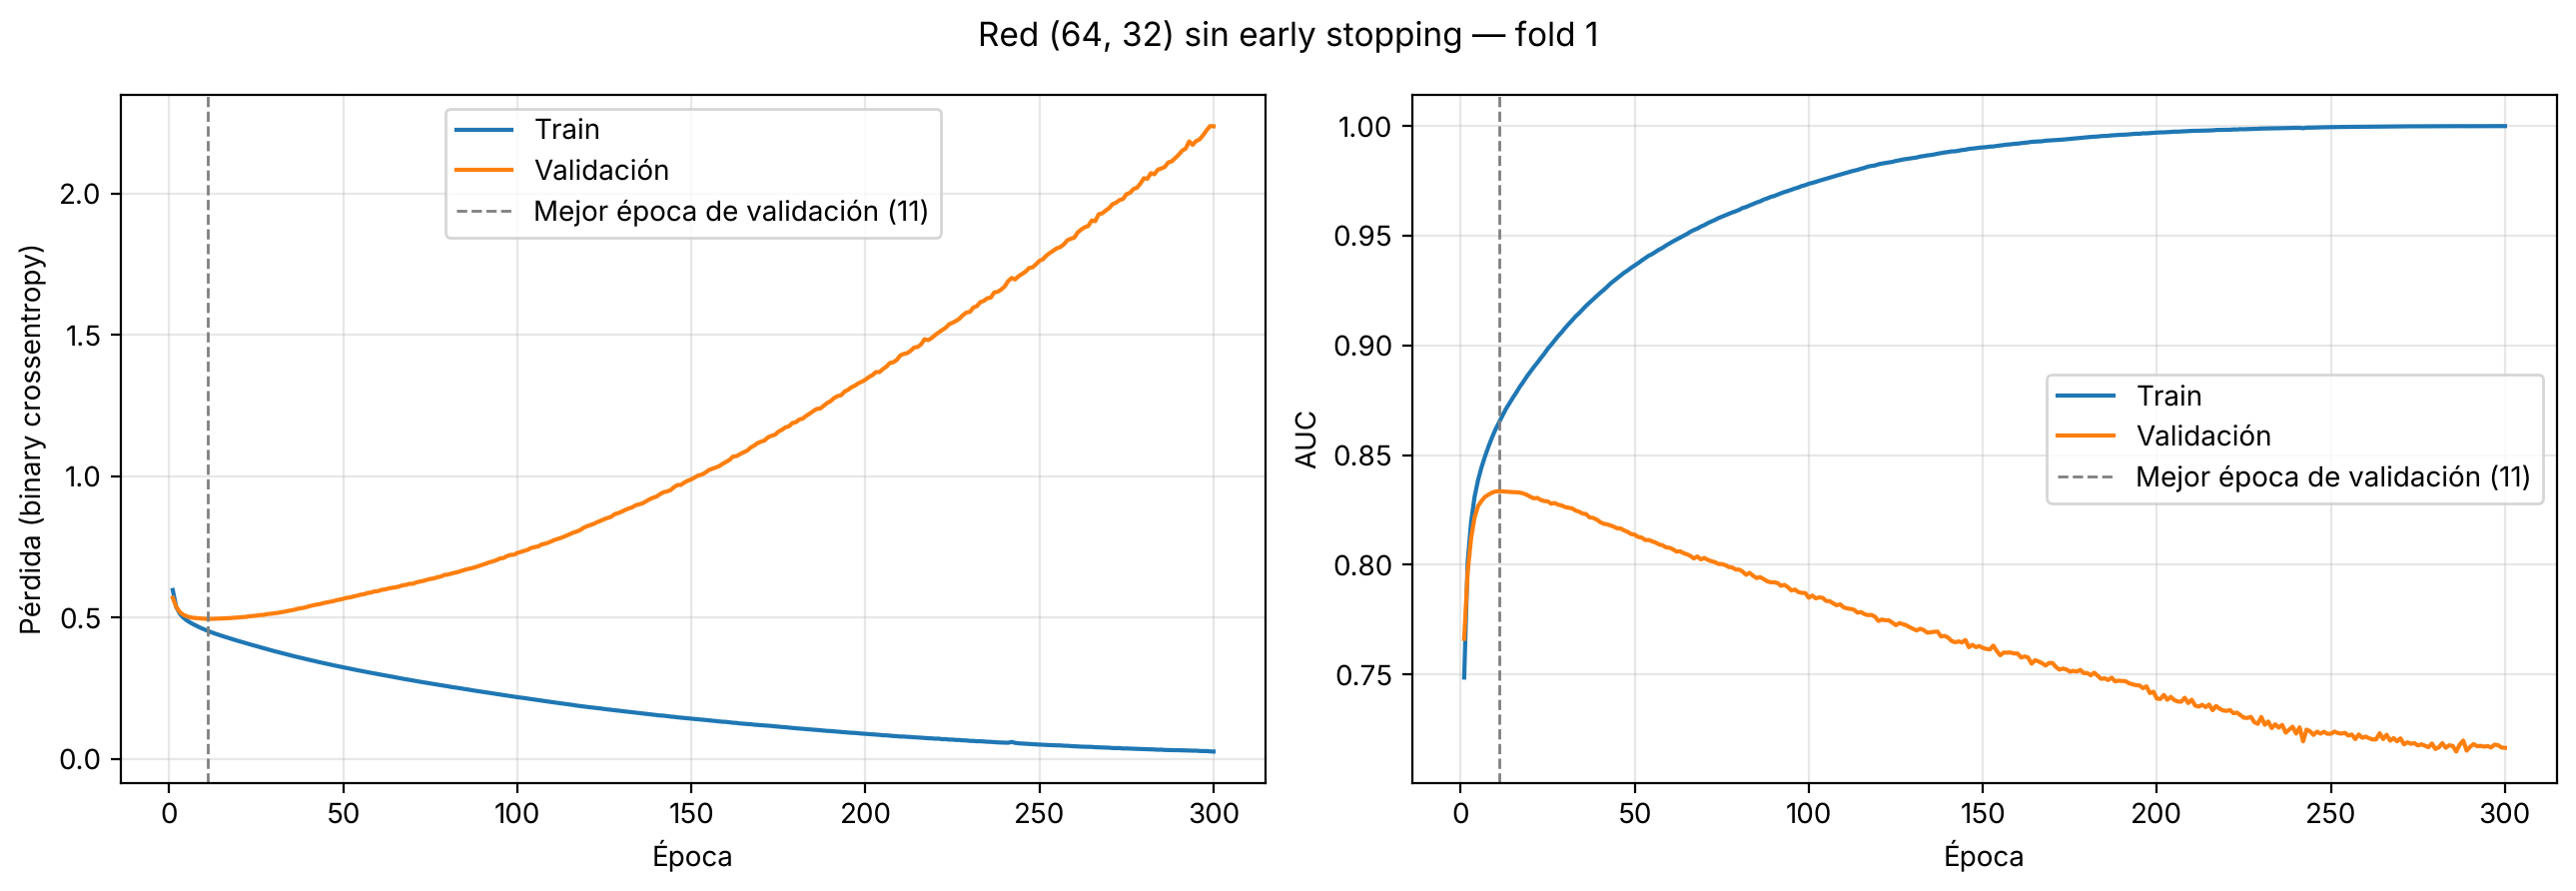

Época  11: pérdida val 0.496 | AUC train 0.865 | AUC val 0.834
Época 100: pérdida val 0.729 | AUC train 0.974 | AUC val 0.785
Época 300: pérdida val 2.237 | AUC train 1.000 | AUC val 0.717


In [4]:
import matplotlib.pyplot as plt

def plot_historial(historia, titulo, epoca_parada=None):
    # Curvas de pérdida y AUC por época, en train y validación (adaptado del práctico)
    epocas = range(1, len(historia['loss']) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for ax, metrica, nombre in [(axes[0], 'loss', 'Pérdida (binary crossentropy)'), (axes[1], 'auc', 'AUC')]:
        ax.plot(epocas, historia[metrica], label='Train')
        ax.plot(epocas, historia[f'val_{metrica}'], label='Validación')
        if epoca_parada:
            ax.axvline(epoca_parada, color='gray', linestyle='--', linewidth=1,
                       label=f'Mejor época de validación ({epoca_parada})')
        ax.set_xlabel('Época')
        ax.set_ylabel(nombre)
        ax.legend()
        ax.grid(alpha=0.3)
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()

# Primer fold de la CV común: se entrena con el train del fold y se mide en su validación
idx_train, idx_val = next(crear_cv().split(X, y))
prep_fold = crear_preprocesador().fit(X.iloc[idx_train])
X_tr, X_va = prep_fold.transform(X.iloc[idx_train]), prep_fold.transform(X.iloc[idx_val])
y_tr, y_va = y.iloc[idx_train], y.iloc[idx_val]

red_fold = RedNeuronal(capas=(64, 32), early_stopping=False, epocas=300)
red_fold.fit(X_tr, y_tr, validation_data=(X_va, y_va))
historia = red_fold.historia_

mejor_epoca = int(np.argmin(historia['val_loss'])) + 1
plot_historial(historia, 'Red (64, 32) sin early stopping — fold 1', epoca_parada=mejor_epoca)

for epoca in [mejor_epoca, 100, 300]:
    print(f"Época {epoca:3d}: pérdida val {historia['val_loss'][epoca - 1]:.3f} | "
          f"AUC train {historia['auc'][epoca - 1]:.3f} | AUC val {historia['val_auc'][epoca - 1]:.3f}")

La red aprende muy rápido: la pérdida de validación llega a su mínimo en la **época 11** (AUC de validación 0,834) y desde ahí **sube sin parar**, mientras la de train sigue bajando. Es el sobreajuste descrito en el práctico: la red empieza a memorizar las películas del train. En la época 100, la que usa el primer modelo del práctico, el AUC de train ya es 0,974 y el de validación bajó a 0,785; en la época 300 el train llega a 1,000 y la validación cae a 0,717, peor que el árbol de clasificación.

La conclusión es que en este problema la cantidad de épocas es el hiperparámetro más importante, y que conviene dejar que la decida el **early stopping** (como en el tercer modelo del práctico) en lugar de fijarla de antemano.

### 4.4 Baseline

Se evalúa con la CV de 5 folds la red del práctico tal cual (100 épocas, sin early stopping ni dropout) y la misma red con **early stopping** (hasta 500 épocas con paciencia de 30, como en el tercer modelo del práctico). La segunda solo agrega el criterio de parada.

In [5]:
baseline = evaluar(RedNeuronal(capas=(64, 32), early_stopping=False, epocas=100), X, y,
                   capas='64-32', dropout=0.0, learning_rate=0.001, early_stopping='no (100 épocas)')
baseline_es = evaluar(RedNeuronal(capas=(64, 32)), X, y,
                      capas='64-32', dropout=0.0, learning_rate=0.001, early_stopping='sí')

COLS_TABLA = ['capas', 'dropout', 'learning_rate',
              'auc', 'auc_std', 'auc_train', 'accuracy', 'precision', 'recall', 'f1']

def redondear(tabla):
    # Redondea las métricas a 3 decimales sin tocar los hiperparámetros (learning_rate = 0.0001)
    metricas = ['auc', 'auc_std', 'auc_train', 'accuracy', 'precision', 'recall', 'f1', 'diferencia_train_val']
    return tabla.round({c: 3 for c in metricas if c in tabla.columns})

redondear(pd.DataFrame([baseline, baseline_es], index=['baseline (práctico)', 'baseline + early stopping'])[
    ['early_stopping'] + COLS_TABLA])

,early_stopping,capas,dropout,learning_rate,auc,auc_std,auc_train,accuracy,precision,recall,f1
baseline (práctico),no (100 épocas),64-32,0.0,0.001,0.792,0.025,0.975,0.716,0.723,0.695,0.708
baseline + early stopping,sí,64-32,0.0,0.001,0.830,0.012,0.877,0.752,0.775,0.701,0.736


La red del práctico tal cual obtiene un **AUC de 0,792 ± 0,025 en validación con 0,975 en train**: sobreajusta mucho, y queda por debajo de la regresión logística (0,815). Además es el resultado con más desvío entre folds de todos los modelos (0,025), porque después de 100 épocas el modelo depende mucho de las películas particulares de cada fold.

Agregando solo el early stopping, la misma arquitectura sube a **0,830 ± 0,012** con 0,877 en train. La mejora (+0,038) es más de tres veces el desvío entre folds, y el desvío se reduce a la mitad. Con este único cambio la red ya supera al Random Forest ajustado (0,825) y queda cerca de AdaBoost (0,831) y Gradient Boosting (0,836).

### 4.5 Búsqueda de hiperparámetros (grid search)

Se prueban **todas las combinaciones** de:

| Hiperparámetro | Valores | Qué controla |
|---|---|---|
| `capas` | 16 · 64-32 · 128-64-32 | Arquitectura: una capa oculta chica, las dos capas del práctico, o tres capas en forma de embudo. Más capas y neuronas dan más capacidad (y más riesgo de sobreajuste). |
| `dropout` | 0, 0.2, 0.5 | Regularización: fracción de neuronas que se apagan al azar en cada paso del entrenamiento, para que la red no dependa de caminos específicos. |
| `learning_rate` | 0.0001, 0.001, 0.01 | Tamaño de los pasos del optimizador Adam. Muy chico aprende lento; muy grande puede saltar por encima del mínimo. |

Son 3 × 3 × 3 = **27 combinaciones**, todas con early stopping (hasta 500 épocas, paciencia de 30) y `batch_size = 32`, evaluadas con la misma CV de 5 folds. La cantidad de épocas no se incluye en la grilla porque la decide el early stopping en cada entrenamiento. La tabla completa se guarda en `resultados/Red_Neuronal/red_neuronal_grilla.csv`, y acá se muestran las 10 mejores.

La celda tarda bastante (unos 40 minutos en una computadora de 4 núcleos): entrena 27 × 5 redes. Las más lentas son las de `learning_rate = 0.0001`, que necesitan muchas más épocas antes de que actúe el early stopping.

In [6]:
import itertools

def crear_red(capas, dropout, learning_rate):
    # Traduce la arquitectura de la grilla ('64-32') a la tupla que espera la clase ((64, 32))
    return RedNeuronal(capas=tuple(int(n) for n in str(capas).split('-')),
                       dropout=float(dropout), learning_rate=float(learning_rate))

GRILLA = {
    'capas': ['16', '64-32', '128-64-32'],
    'dropout': [0.0, 0.2, 0.5],
    'learning_rate': [0.0001, 0.001, 0.01],
}

filas = []
for capas, dropout, learning_rate in itertools.product(*GRILLA.values()):
    filas.append(evaluar(crear_red(capas, dropout, learning_rate), X, y,
                         capas=capas, dropout=dropout, learning_rate=learning_rate))

grilla = pd.DataFrame(filas).sort_values('auc', ascending=False).reset_index(drop=True)

grilla.to_csv(f'{CARPETA_RESULTADOS}/red_neuronal_grilla.csv', index=False)
print(f'{len(grilla)} combinaciones evaluadas')

27 combinaciones evaluadas


**Las 10 mejores combinaciones** (ordenadas por AUC de validación), comparadas con los dos baselines:

In [7]:
top10 = grilla.head(10)[COLS_TABLA].copy()
top10.index = range(1, 11)
top10.loc['baseline'] = pd.Series(baseline)[COLS_TABLA]
top10.loc['baseline + ES'] = pd.Series(baseline_es)[COLS_TABLA]
redondear(top10)

,capas,dropout,learning_rate,auc,auc_std,auc_train,accuracy,precision,recall,f1
1,128-64-32,0.5,0.0010,0.832,0.011,0.871,0.748,0.803,0.650,0.717
2,128-64-32,0.5,0.0001,0.831,0.011,0.869,0.751,0.805,0.654,0.721
3,128-64-32,0.0,0.0010,0.830,0.011,0.869,0.751,0.805,0.654,0.721
4,16,0.0,0.0001,0.830,0.011,0.856,0.751,0.773,0.702,0.736
5,64-32,0.0,0.0010,0.830,0.012,0.877,0.752,0.775,0.701,0.736
6,64-32,0.5,0.0010,0.830,0.010,0.876,0.746,0.775,0.686,0.727
7,128-64-32,0.2,0.0010,0.830,0.011,0.873,0.745,0.777,0.680,0.724
8,64-32,0.0,0.0001,0.830,0.012,0.876,0.748,0.771,0.699,0.733
9,16,0.0,0.0010,0.830,0.012,0.860,0.747,0.765,0.704,0.732
10,128-64-32,0.2,0.0001,0.829,0.011,0.873,0.743,0.776,0.676,0.722


### 4.6 Efecto de los hiperparámetros

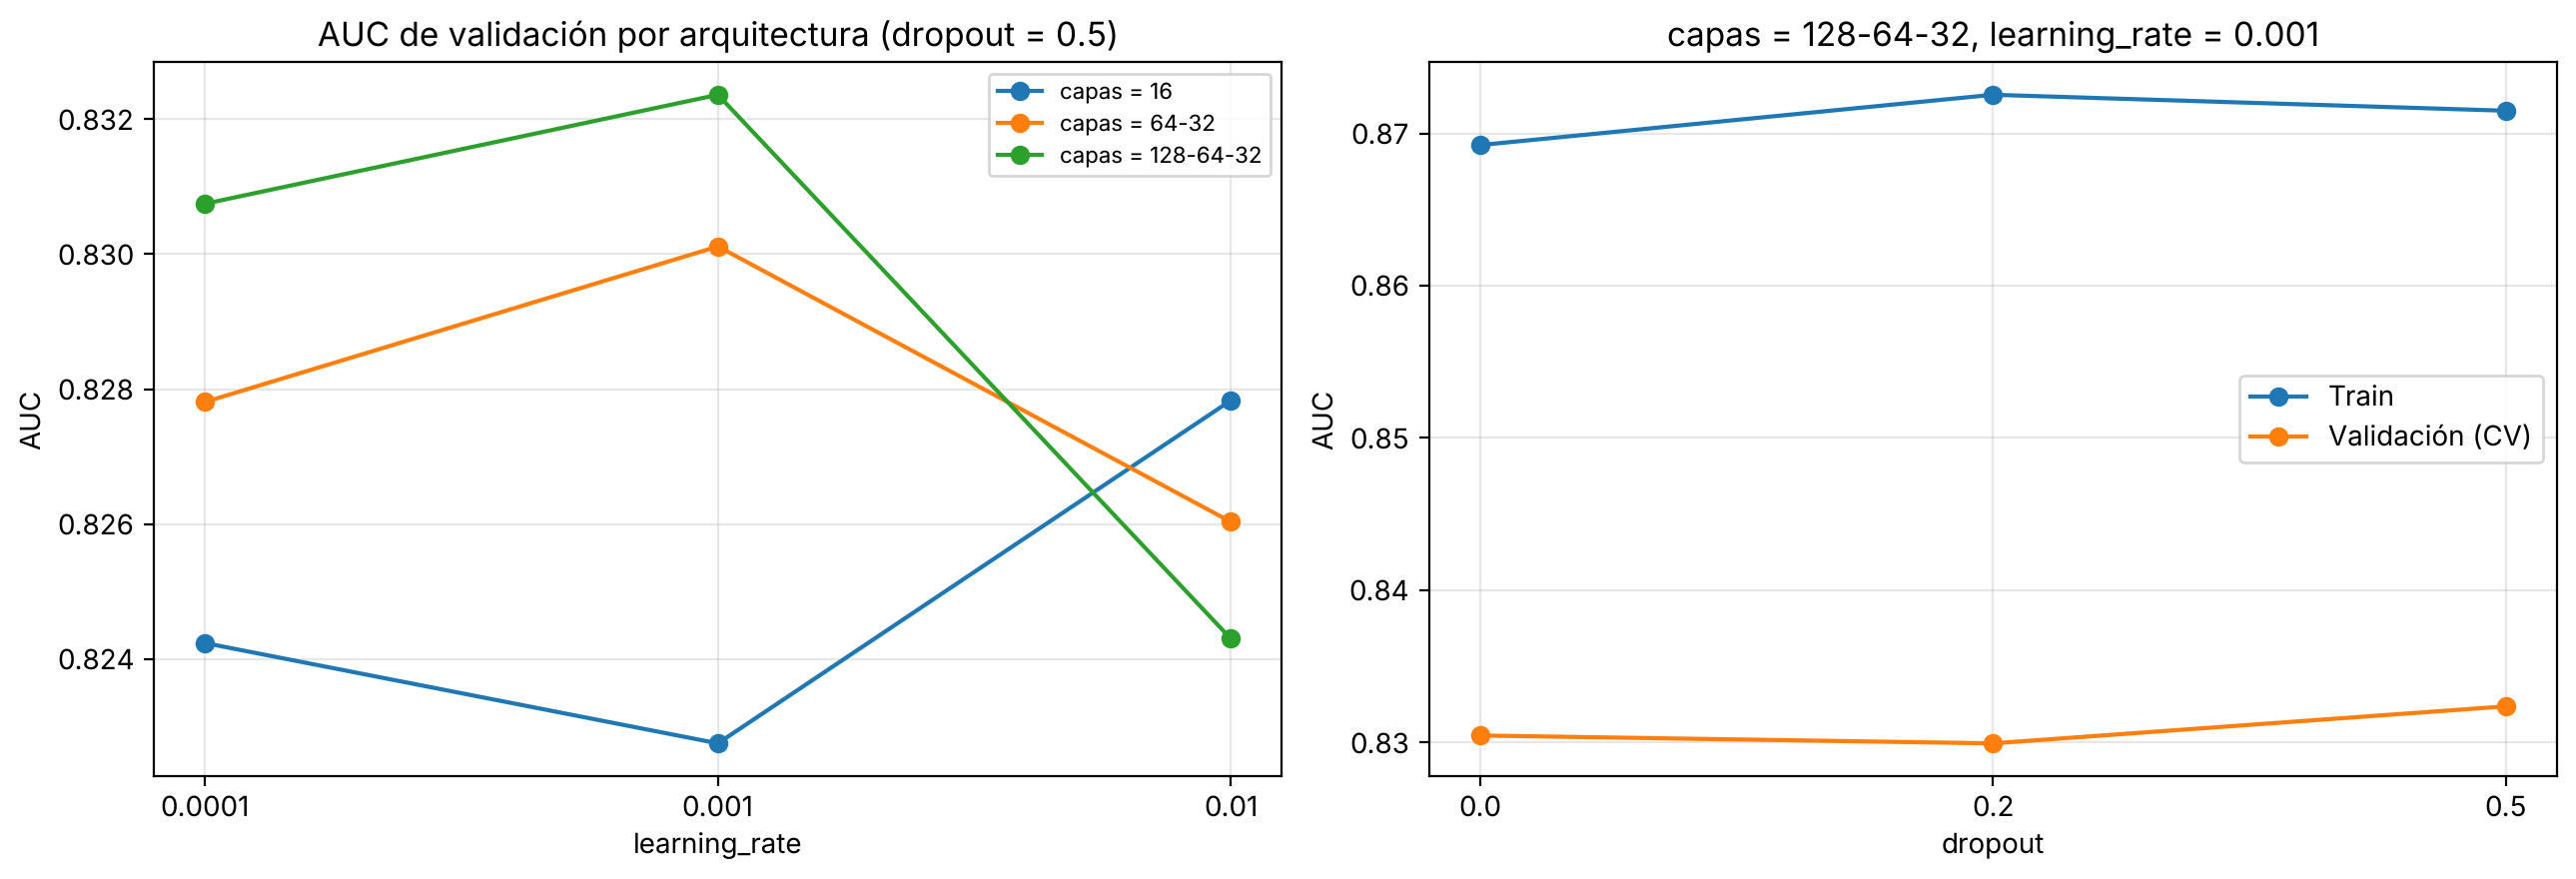

In [8]:
mejor = grilla.iloc[0]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Izquierda: AUC de validación según learning_rate para cada arquitectura (dropout del mejor)
sub = grilla[grilla['dropout'] == mejor['dropout']]
for capas in GRILLA['capas']:
    s = sub[sub['capas'] == capas].sort_values('learning_rate')
    axes[0].plot(s['learning_rate'].astype(str), s['auc'], 'o-', label=f'capas = {capas}')
axes[0].set_title(f"AUC de validación por arquitectura (dropout = {mejor['dropout']})")
axes[0].set_xlabel('learning_rate')
axes[0].legend(fontsize=8)

# Derecha: AUC en train y validación según dropout (arquitectura y learning_rate del mejor)
sub = grilla[(grilla['capas'] == mejor['capas']) & (grilla['learning_rate'] == mejor['learning_rate'])]
sub = sub.sort_values('dropout')
axes[1].plot(sub['dropout'].astype(str), sub['auc_train'], 'o-', label='Train')
axes[1].plot(sub['dropout'].astype(str), sub['auc'], 'o-', label='Validación (CV)')
axes[1].set_title(f"capas = {mejor['capas']}, learning_rate = {mejor['learning_rate']}")
axes[1].set_xlabel('dropout')
axes[1].legend()

for ax in axes:
    ax.set_ylabel('AUC')
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

- **Izquierda:** AUC de validación según el `learning_rate` para cada arquitectura, con `dropout = 0,5`. Para las dos redes más grandes el mejor valor es el de Adam por defecto (0,001), y con 0,01 el resultado baja (0,824 con tres capas): con pasos grandes la pérdida de validación oscila y el early stopping corta en un punto peor. Para la red de una capa de 16 neuronas el orden se invierte. De todos modos, todas las diferencias están entre 0,823 y 0,832, por debajo del desvío entre folds (0,011).
- **Derecha:** AUC en train y en validación según el `dropout`, con la arquitectura y el `learning_rate` del mejor. El dropout casi no cambia nada: la validación pasa de 0,830 a 0,832 y el train se mantiene en 0,87. El motivo es que el early stopping ya cumple el papel de regularizador: corta el entrenamiento antes de que la red llegue a memorizar el train, así que al dropout le queda poco sobreajuste por corregir.

### 4.7 Mejor configuración

Se elige la combinación con **mayor AUC de validación**. Si hay otras dentro de un desvío estándar, se muestran para considerar la más simple (menos neuronas) y la de menor distancia entre train y validación.

In [9]:
print('Mejor red neuronal:')
print(f"  capas={mejor['capas']}, dropout={mejor['dropout']}, learning_rate={mejor['learning_rate']}")
print(f"  AUC validación = {mejor['auc']:.3f} ± {mejor['auc_std']:.3f}")
print(f"  AUC train      = {mejor['auc_train']:.3f}  (diferencia {mejor['auc_train'] - mejor['auc']:.3f})")
print(f"  Mejora sobre el baseline del práctico: +{mejor['auc'] - baseline['auc']:.3f} de AUC")
print(f"  Mejora sobre el baseline con early stopping: +{mejor['auc'] - baseline_es['auc']:.3f} de AUC")

empatadas = grilla[grilla['auc'] >= mejor['auc'] - mejor['auc_std']]
print(f"\nCombinaciones dentro de un desvío del mejor: {len(empatadas)} (se muestran las 10 primeras)")
redondear(empatadas.head(10)[COLS_TABLA].assign(diferencia_train_val=empatadas['auc_train'].head(10) - empatadas['auc'].head(10)))

Mejor red neuronal:
  capas=128-64-32, dropout=0.5, learning_rate=0.001
  AUC validación = 0.832 ± 0.011
  AUC train      = 0.871  (diferencia 0.039)
  Mejora sobre el baseline del práctico: +0.041 de AUC
  Mejora sobre el baseline con early stopping: +0.002 de AUC

Combinaciones dentro de un desvío del mejor: 26 (se muestran las 10 primeras)


,capas,dropout,learning_rate,auc,auc_std,auc_train,accuracy,precision,recall,f1,diferencia_train_val
0,128-64-32,0.5,0.0010,0.832,0.011,0.871,0.748,0.803,0.650,0.717,0.039
1,128-64-32,0.5,0.0001,0.831,0.011,0.869,0.751,0.805,0.654,0.721,0.038
2,128-64-32,0.0,0.0010,0.830,0.011,0.869,0.751,0.805,0.654,0.721,0.039
3,16,0.0,0.0001,0.830,0.011,0.856,0.751,0.773,0.702,0.736,0.025
4,64-32,0.0,0.0010,0.830,0.012,0.877,0.752,0.775,0.701,0.736,0.046
5,64-32,0.5,0.0010,0.830,0.010,0.876,0.746,0.775,0.686,0.727,0.045
6,128-64-32,0.2,0.0010,0.830,0.011,0.873,0.745,0.777,0.680,0.724,0.043
7,64-32,0.0,0.0001,0.830,0.012,0.876,0.748,0.771,0.699,0.733,0.046
8,16,0.0,0.0010,0.830,0.012,0.860,0.747,0.765,0.704,0.732,0.031
9,128-64-32,0.2,0.0001,0.829,0.011,0.873,0.743,0.776,0.676,0.722,0.044


**Elección:** `capas = 128-64-32`, `dropout = 0.5`, `learning_rate = 0.001` (con `batch_size = 32` y early stopping con paciencia de 30), con AUC de validación de 0,832 ± 0,011. La mejora sobre la red del práctico es grande (+0,041), pero casi toda se debe al early stopping: respecto del baseline con early stopping la mejora es de solo 0,002. **26 de las 27 combinaciones** quedan dentro de un desvío de la mejor, así que ni la arquitectura, ni el dropout, ni el `learning_rate` hacen una diferencia que se pueda distinguir del ruido.

Entre las empatadas hay opciones mucho más simples, como una sola capa de 16 neuronas con `learning_rate = 0.0001` (0,830, con una diferencia train-validación de 0,025). Se mantiene la de mayor AUC de validación, con el mismo criterio que en los otros modelos. La diferencia entre train y validación de la elegida (0,039) es la más baja de los modelos no lineales (Random Forest 0,136, AdaBoost 0,061, Gradient Boosting 0,090); solo la regresión logística tiene una menor (0,006).

## 5. Análisis del modelo elegido

Se reconstruye la mejor red de la grilla y se analiza: en cuántas épocas para el early stopping en cada fold, la matriz de confusión (con las predicciones de validación de la CV), la comparación con los modelos anteriores y la importancia de las variables.

In [10]:
mejor_red = crear_red(mejor['capas'], mejor['dropout'], mejor['learning_rate'])
mejor_red

RedNeuronal(capas=(128, 64, 32), dropout=0.5)

### 5.1 Entrenamiento en cada fold

Se entrena la red elegida en cada uno de los 5 folds (preprocesador + red, igual que en `evaluar`) y se guarda en qué época se detuvo el early stopping y el AUC de validación del fold. Los modelos entrenados se reutilizan en la sección 5.4.

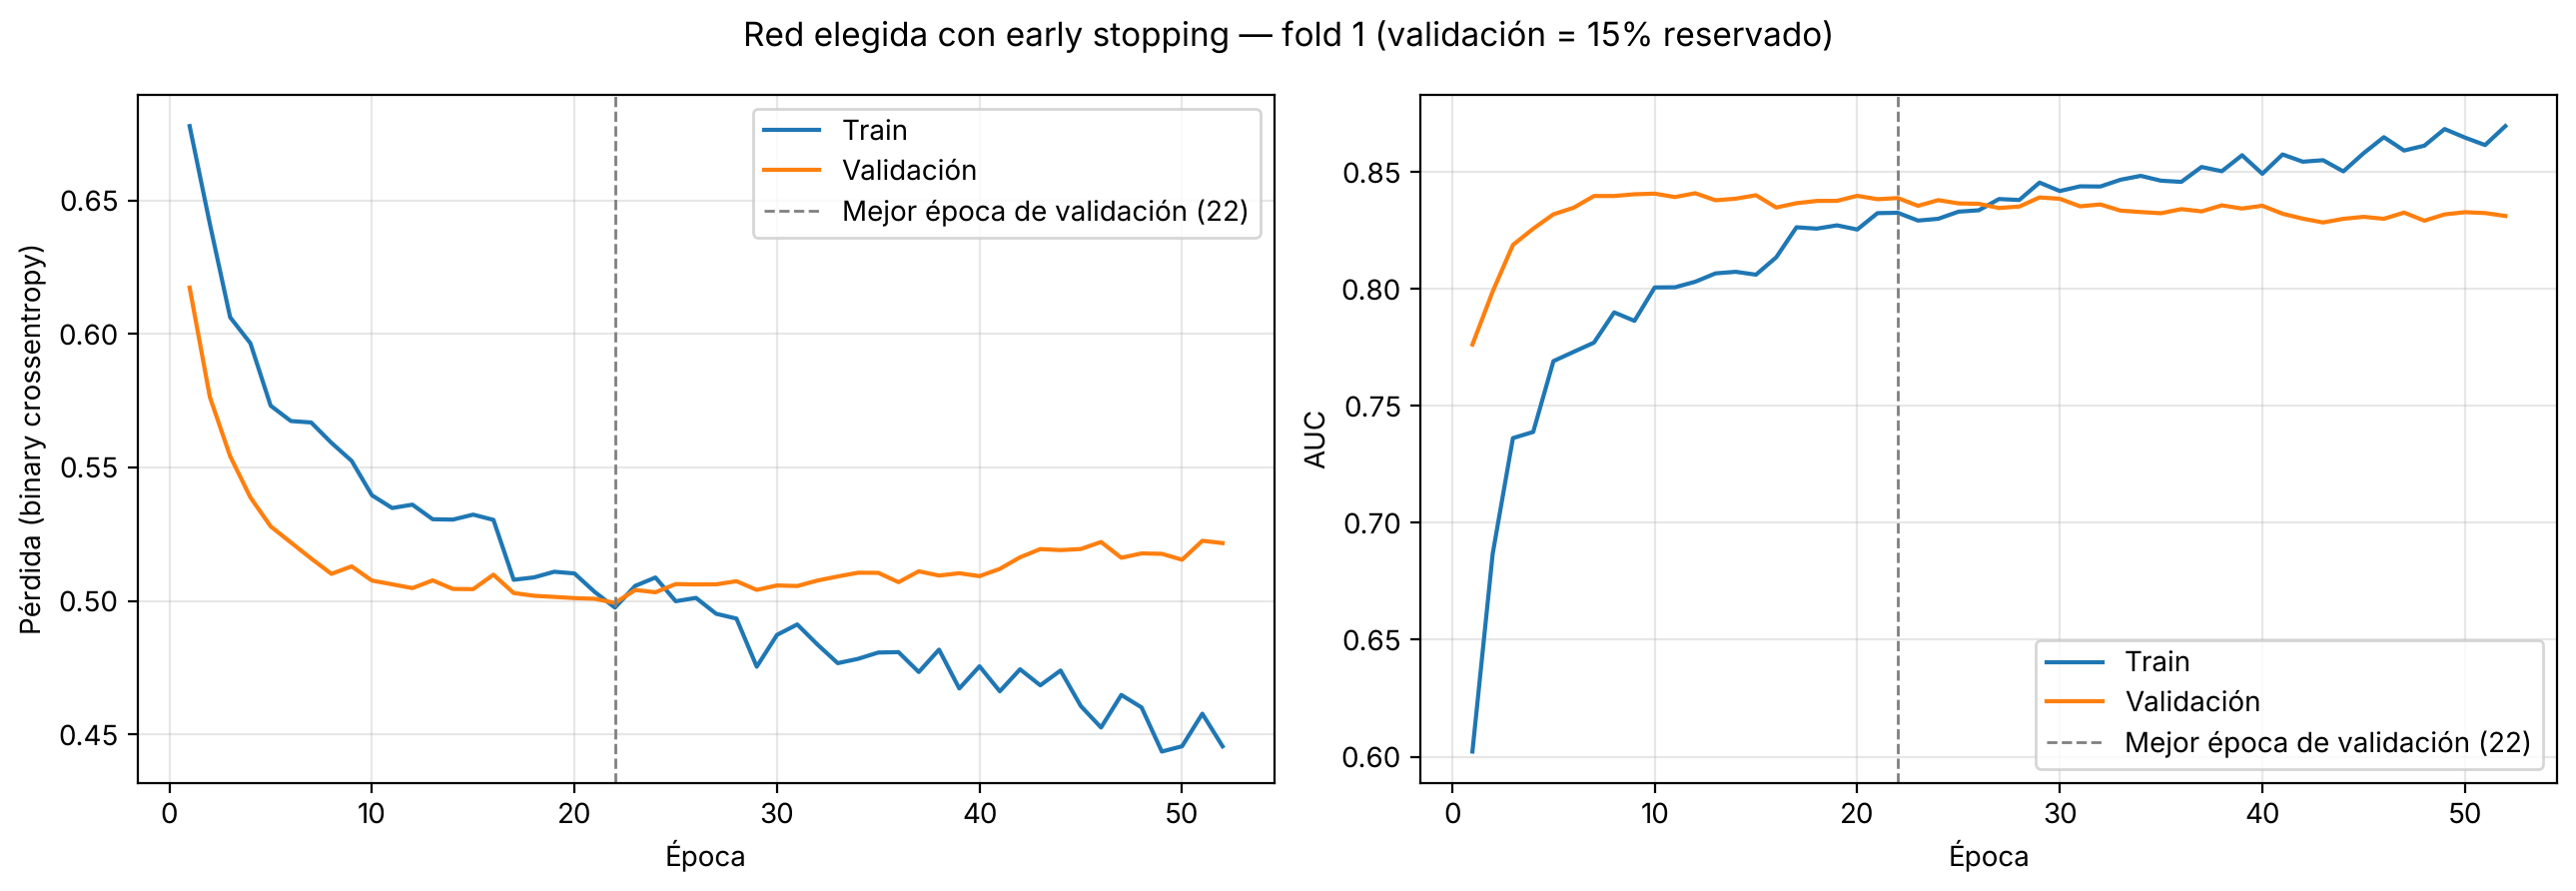

,epocas_entrenadas,mejor_epoca,auc_val
fold,,,
1,52,22,0.831
2,62,32,0.826
3,69,39,0.849
4,63,33,0.817
5,72,42,0.839


In [11]:
from sklearn.base import clone
from sklearn.metrics import roc_auc_score

pipes_folds, filas_folds = [], []
for fold, (idx_train, idx_val) in enumerate(crear_cv().split(X, y), start=1):
    pipe = crear_pipeline(clone(mejor_red)).fit(X.iloc[idx_train], y.iloc[idx_train])
    red = pipe.named_steps['modelo']
    pipes_folds.append((pipe, idx_val))
    filas_folds.append({
        'fold': fold,
        'epocas_entrenadas': red.epocas_entrenadas_,
        'mejor_epoca': int(np.argmin(red.historia_['val_loss'])) + 1,
        'auc_val': roc_auc_score(y.iloc[idx_val], pipe.predict_proba(X.iloc[idx_val])[:, 1]),
    })
folds = pd.DataFrame(filas_folds).set_index('fold')

red_fold1 = pipes_folds[0][0].named_steps['modelo']
plot_historial(red_fold1.historia_, f"Red elegida con early stopping — fold 1 (validación = 15% reservado)",
               epoca_parada=folds.loc[1, 'mejor_epoca'])
folds.round(3)

El early stopping detiene el entrenamiento entre las épocas 52 y 72, y la mejor época (la que se restaura) está entre la 22 y la 42, muy por debajo de las 100 que usaba el primer modelo del práctico. El AUC por fold va de 0,817 a 0,849; el fold 4 es el más difícil, igual que para los modelos de boosting.

En el gráfico, durante las primeras épocas la curva de train queda **por debajo** de la de validación. No es un error: Keras calcula la pérdida y el AUC de train con el dropout activo (la mitad de las neuronas apagadas), mientras que la validación se calcula con la red completa. A partir de la mejor época la pérdida de validación empieza a subir lentamente mientras la de train sigue bajando, que es justo lo que el early stopping detecta.

### 5.2 Matriz de confusión

Cada película se predice con el modelo del fold en el que quedó en validación (o sea, con un modelo que no la vio al entrenar). Se usa el umbral por defecto de 0,5 sobre la probabilidad.

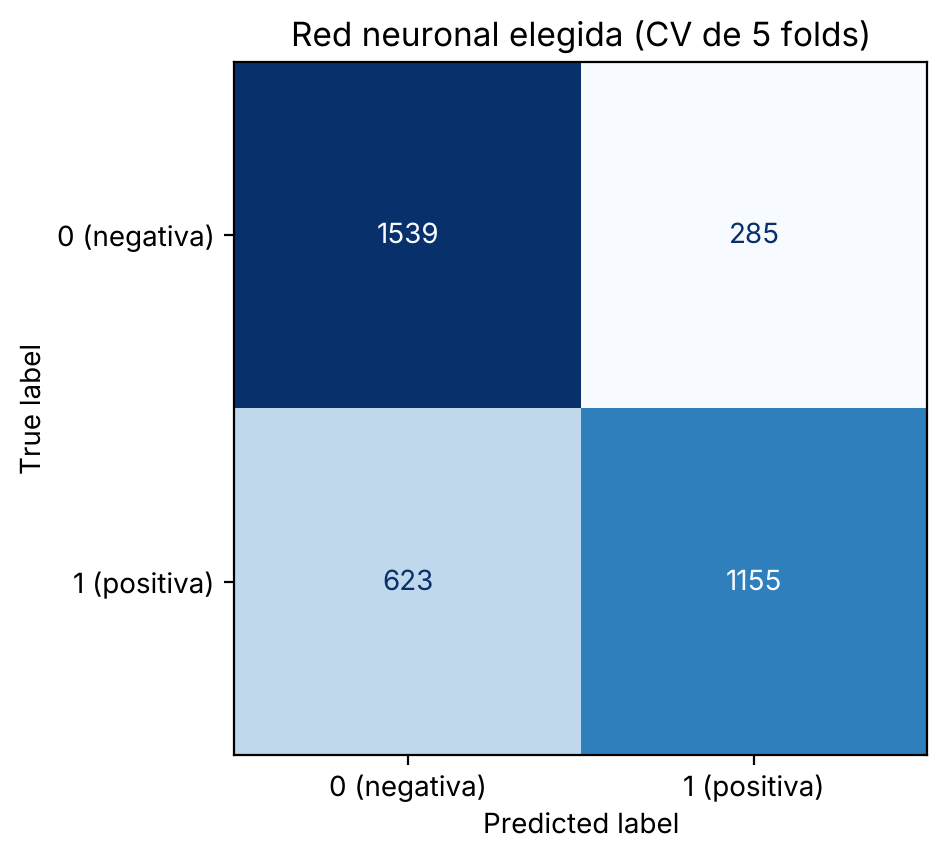

Verdaderos negativos: 1539  | Falsos positivos: 285
Falsos negativos:     623  | Verdaderos positivos: 1155
De las películas con opinión negativa, detecta el 84%
De las películas con opinión positiva, detecta el 65% (recall)
De las que predice como positivas, acierta el 80% (precision)


In [12]:
fig, ax = plt.subplots(figsize=(5, 4.5))
cm = matriz_confusion(mejor_red, X, y, titulo='Red neuronal elegida (CV de 5 folds)', ax=ax)
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f'Verdaderos negativos: {tn}  | Falsos positivos: {fp}')
print(f'Falsos negativos:     {fn}  | Verdaderos positivos: {tp}')
print(f'De las películas con opinión negativa, detecta el {tn / (tn + fp):.0%}')
print(f'De las películas con opinión positiva, detecta el {tp / (tp + fn):.0%} (recall)')
print(f'De las que predice como positivas, acierta el {tp / (tp + fp):.0%} (precision)')

Clasifica bien el 84% de las películas con opinión negativa y el 65% de las positivas. Comparado con Gradient Boosting (79% y 71%), comete bastantes menos falsos positivos (285 contra 388) pero más falsos negativos (623 contra 507), y la accuracy queda prácticamente igual (0,748 contra 0,752). Es decir, con el umbral de 0,5 la red es más conservadora para predecir opinión positiva: tiene la precision más alta de todos los modelos (0,803) y el recall más bajo (0,650).

Esto depende solo del umbral y no afecta al AUC, que mide cómo quedan ordenadas las películas por probabilidad. Igual que todos los modelos anteriores, se equivoca más con las positivas que con las negativas, pero en la red la diferencia es más marcada.

### 5.3 Comparación con los modelos anteriores

Se compara la red (baselines y ajustada) con los modelos elegidos en las notebooks anteriores, leídos de sus archivos en `resultados/`. Todos usan los mismos folds, así que los números son directamente comparables.

In [13]:
def leer_final(ruta):
    # En Colab no está la carpeta resultados: se lee del repo
    if not os.path.exists(ruta):
        ruta = 'https://raw.githubusercontent.com/juanmareolon/OBL_ML/main/' + ruta
    return pd.read_csv(ruta).iloc[0]

def fila(nombre, r):
    return {'modelo': nombre, 'auc_cv': r['auc'], 'auc_cv_std': r['auc_std'], 'auc_train': r['auc_train'],
            'accuracy': r['accuracy'], 'precision': r['precision'], 'recall': r['recall'], 'f1': r['f1']}

filas = [fila('Red neuronal (baseline)', baseline), fila('Red neuronal (baseline + ES)', baseline_es),
         fila('Red neuronal (ajustada)', mejor)]
for ruta in ['resultados/Arbol_Clasificacion/arbol_final.csv',
             'resultados/Regresion_Logistica/logistica_final.csv',
             'resultados/Random_Forest/random_forest_final.csv',
             'resultados/Boosting/adaboost_final.csv',
             'resultados/Boosting/gradient_boosting_final.csv']:
    r = leer_final(ruta)
    filas.append({c: r[c] for c in ['modelo', 'auc_cv', 'auc_cv_std', 'auc_train',
                                    'accuracy', 'precision', 'recall', 'f1']})

comparacion_modelos = pd.DataFrame(filas).set_index('modelo').sort_values('auc_cv', ascending=False)
comparacion_modelos.round(3)

,auc_cv,auc_cv_std,auc_train,accuracy,precision,recall,f1
modelo,,,,,,,
Gradient Boosting,0.836,0.013,0.926,0.752,0.766,0.715,0.740
Red neuronal (ajustada),0.832,0.011,0.871,0.748,0.803,0.650,0.717
AdaBoost,0.831,0.013,0.892,0.751,0.763,0.719,0.740
Red neuronal (baseline + ES),0.830,0.012,0.877,0.752,0.775,0.701,0.736
Random Forest,0.825,0.011,0.960,0.743,0.761,0.698,0.728
Regresión logística,0.815,0.009,0.821,0.744,0.751,0.721,0.736
Red neuronal (baseline),0.792,0.025,0.975,0.716,0.723,0.695,0.708
Árbol de clasificación,0.769,0.013,0.813,0.697,0.705,0.669,0.685


**Lectura:**

- La red neuronal ajustada queda **segunda** con 0,832 de AUC en validación, detrás de Gradient Boosting (0,836) y apenas por encima de AdaBoost (0,831). La diferencia con Gradient Boosting (0,004) es menor al desvío entre folds (0,011), así que en validación los tres están prácticamente empatados.
- La red con la arquitectura del práctico y early stopping ya alcanza 0,830: en esta red, el ajuste de hiperparámetros aporta mucho menos que decidir bien cuándo dejar de entrenar.
- Respecto de la regresión logística (que equivale a una red sin capas ocultas), la red mejora 0,017 de AUC: las capas ocultas le permiten captar relaciones no lineales e interacciones entre variables, igual que los modelos de árboles.
- Es el modelo no lineal con **menor diferencia entre train y validación** (0,871 contra 0,832), por el early stopping.

### 5.4 Importancia de variables (por permutación)

Una red neuronal no tiene una medida de importancia propia como `feature_importances_` de los árboles, ni coeficientes interpretables uno a uno como la regresión logística: cada variable entra en todas las neuronas de la primera capa y se mezcla con las demás. Por eso se usa la **importancia por permutación**: en el fold de validación se desordena al azar una variable (rompiendo su relación con `opinion`) y se mide cuánto baja el AUC. Cuanto más baja, más depende la red de esa variable.

Se calcula sobre las variables originales (antes del one-hot, así el género o el idioma cuentan como una sola variable), con los 5 modelos de la sección 5.1, cada uno en su fold de validación, y 10 permutaciones por variable. El resultado es el promedio de la caída de AUC entre folds.

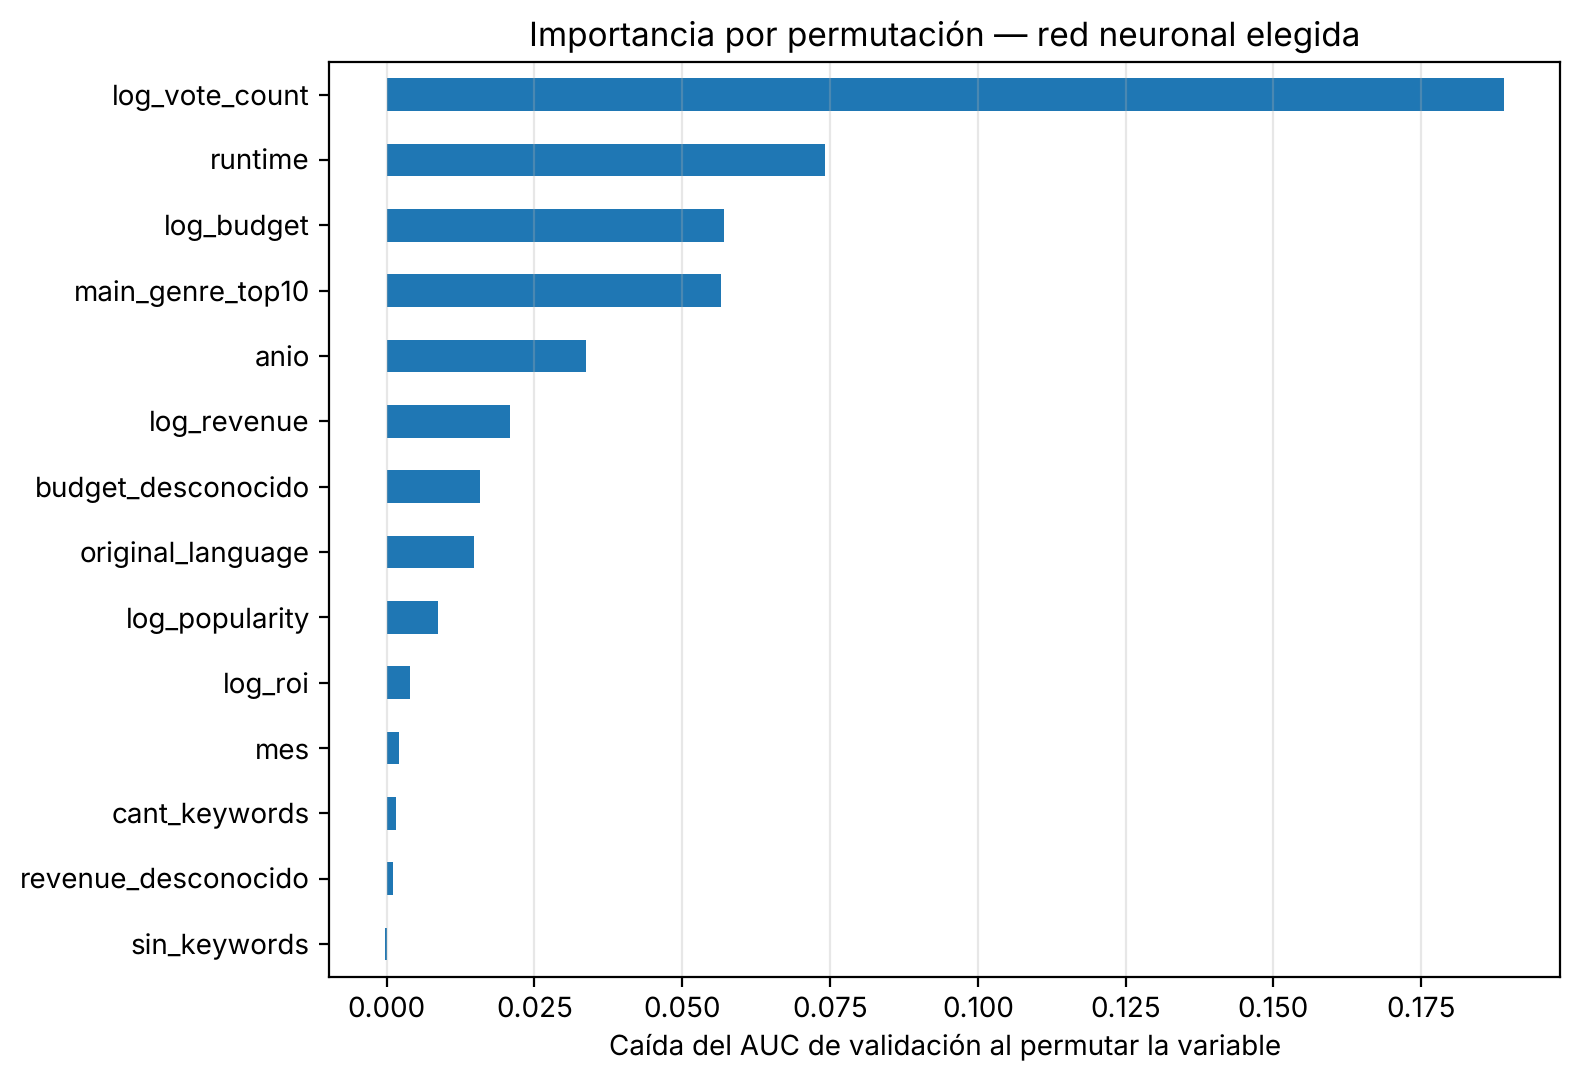

,caida_auc
log_vote_count,0.1890
runtime,0.0741
log_budget,0.0571
main_genre_top10,0.0566
anio,0.0337
log_revenue,0.0208
budget_desconocido,0.0158
original_language,0.0147
log_popularity,0.0087
log_roi,0.0040


In [14]:
from sklearn.inspection import permutation_importance

caidas = []
for pipe, idx_val in pipes_folds:
    r = permutation_importance(pipe, X.iloc[idx_val], y.iloc[idx_val], scoring='roc_auc',
                               n_repeats=10, random_state=SEED)
    caidas.append(pd.Series(r.importances_mean, index=X.columns))
importancia_perm = pd.concat(caidas, axis=1).mean(axis=1).sort_values(ascending=False)
importancia_perm = importancia_perm.drop('director')  # no se usa en el preprocesador (siempre 0)

fig, ax = plt.subplots(figsize=(8, 5.5))
importancia_perm.iloc[::-1].plot.barh(ax=ax)
ax.set_title('Importancia por permutación — red neuronal elegida')
ax.set_xlabel('Caída del AUC de validación al permutar la variable')
ax.grid(alpha=0.3, axis='x')
plt.tight_layout()
plt.show()

importancia_perm.round(4).to_frame('caida_auc').head(10)

**Lectura:**

- La variable más importante es, por lejos, la **cantidad de votos**: al permutarla el AUC cae 0,189. Le siguen la duración (0,074), el presupuesto (0,057), el género (0,057) y el año (0,034). Coincide con todos los modelos anteriores, donde votos y duración también eran las dos variables principales.
- El **género** aparece más arriba que en los modelos de árboles. Acá se mide como una sola variable (se permutan juntas todas sus columnas del one-hot) y la importancia por permutación no favorece a las numéricas como la reducción de impureza. Es coherente con la regresión logística, donde Horror, Animation y Drama tenían coeficientes grandes.
- El **ROI** casi no importa (0,004), a diferencia de los árboles, donde estaba entre las primeras. Igual que en la regresión logística, el ROI es redundante con el presupuesto y la recaudación: al desordenarlo, la red sigue teniendo esa información en las otras dos variables. Por eso, en variables correlacionadas la importancia por permutación tiende a subestimar a cada una por separado.

## 6. Submission y resultado en Kaggle

Se entrena la red elegida con **todo** el train (con el mismo early stopping sobre un 15% reservado) y se guardan las **probabilidades** de la clase 1 para las 1201 películas del test (no clases 0/1, porque la métrica de la competencia es AUC). El archivo queda en `kaggle/submission_red_neuronal.csv`.

In [15]:
sub = generar_submission(mejor_red, X, y, X_test, ids_test, f'{CARPETA_KAGGLE}/submission_red_neuronal.csv')

# Chequeos: 1201 filas, sin NaN y probabilidades (no solo 0/1)
assert len(sub) == len(X_test) and sub['opinion'].notna().all()
print(f"Probabilidades entre {sub['opinion'].min():.3f} y {sub['opinion'].max():.3f}, "
      f"{sub['opinion'].nunique()} valores distintos")
sub.head()

Guardado kaggle/submission_red_neuronal.csv (1201 filas)
Probabilidades entre 0.010 y 1.000, 1194 valores distintos


,id,opinion
0,0,0.999633
1,1,0.248702
2,2,0.472741
3,3,0.973197
4,4,0.571630


### Resultado en Kaggle

*Public Score* obtenido al subir `kaggle/submission_red_neuronal.csv`. La fila se guarda en `resultados/Red_Neuronal/red_neuronal_final.csv` para la tabla comparativa entre modelos.

In [16]:
auc_kaggle = 0.83664  # Public Score de submission_red_neuronal.csv

resultado_final = {
    'modelo': 'Red neuronal',
    'hiperparametros': (f"capas={mejor['capas']}, dropout={mejor['dropout']}, "
                        f"learning_rate={mejor['learning_rate']}, batch_size=32, early_stopping (paciencia 30)"),
    'auc_cv': mejor['auc'], 'auc_cv_std': mejor['auc_std'], 'auc_train': mejor['auc_train'],
    'accuracy': mejor['accuracy'], 'precision': mejor['precision'], 'recall': mejor['recall'], 'f1': mejor['f1'],
    'auc_kaggle': auc_kaggle,
}
pd.DataFrame([resultado_final]).to_csv(f'{CARPETA_RESULTADOS}/red_neuronal_final.csv', index=False)
pd.set_option('display.max_colwidth', None)
pd.DataFrame([resultado_final]).round(3)

,modelo,hiperparametros,auc_cv,auc_cv_std,auc_train,accuracy,precision,recall,f1,auc_kaggle
0,Red neuronal,"capas=128-64-32, dropout=0.5, learning_rate=0.001, batch_size=32, early_stopping (paciencia 30)",0.832,0.011,0.871,0.748,0.803,0.65,0.717,0.837


**Interpretación:** la red neuronal obtiene **0,837** en Kaggle, algo más que en la validación cruzada (0,832 ± 0,011). La diferencia (0,004) es menor al desvío entre folds, así que la CV resultó una buena estimación, y es esperable que el puntaje sea levemente mayor porque el modelo final se entrena con todo el train (25% más de películas que en cada fold).

En Kaggle queda tercera: detrás del Random Forest (0,844) y de Gradient Boosting (0,841), y por delante de AdaBoost (0,834), la regresión logística (0,819) y el árbol (0,771). Entre los tres modelos que estaban empatados en la CV, el orden se mantiene (Gradient Boosting, red neuronal, AdaBoost). Como en las notebooks anteriores, las diferencias entre los mejores modelos son de pocas milésimas, del orden de la variación propia de un único conjunto de test, así que para elegir se sigue usando la CV.